In [3]:
import pandas as pd
import numpy as np

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(
    'data/processed/daily_ridership_2025.csv',
    parse_dates=['date'],
    index_col='date'
)['total_rides'].sort_index()

calendar = pd.date_range('2025-01-01', '2025-12-31', freq='D')

holdout_start = pd.Timestamp("2025-10-01")
one_week = pd.Timedelta(days=7)

def calendar_features(dates):
    weekdays = pd.Categorical(dates.day_of_week, categories=range(7))
    features = pd.get_dummies(
        pd.Series(weekdays, index=dates),
        prefix="weekday",
        dtype=float,
    )

    phase = 2 * np.pi * (dates.day_of_year - 1) / 365.25
    features["annual_sin"] = np.sin(phase)
    features["annual_cos"] = np.cos(phase)
    return features


train_dates = df.index[
    (df.index >= df.index.min() + one_week)
    & (df.index < holdout_start)
]

X_train = calendar_features(train_dates)
X_train["rides_last_week"] = df.reindex(train_dates - one_week).to_numpy()

model = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
model.fit(X_train, df.loc[train_dates])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['weekday_0','weekday_1','weekday_2',...,'annual_sin','annual_cos', 'rides_last_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [4]:
blocks = []

for block_start in pd.date_range(holdout_start, df.index.max(), freq="7D"):
    block_end = min(block_start + pd.Timedelta(days=6), df.index.max())
    target_dates = pd.date_range(block_start, block_end, freq="D")

    available_rides = df.loc[df.index < block_start]
    prior_week = available_rides.reindex(target_dates - one_week)

    if prior_week.isna().any():
        raise ValueError(f"Missing prior-week rides for {block_start.date()}.")

    X_test = calendar_features(target_dates)
    X_test["rides_last_week"] = prior_week.to_numpy()

    blocks.append(pd.DataFrame(
        {
            "prior_week": prior_week.to_numpy(),
            "ridge": model.predict(X_test).clip(min=0),
        },
        index=target_dates,
    ))

predictions = pd.concat(blocks)
expected_dates = df.loc[holdout_start:].index
if not predictions.index.equals(expected_dates):
    raise ValueError("Expected one prediction for every holdout date.")

results = predictions.join(df.rename("actual"))
errors = predictions.sub(results["actual"], axis=0)

scores = pd.DataFrame({
    "MAE": errors.abs().mean(),
    "RMSE": errors.pow(2).mean().pow(0.5),
    "Mean signed error": errors.mean(),
})

print(f"Scored {len(results)} days in {len(blocks)} forecast blocks.")
display(scores.round(1))

Scored 92 days in 14 forecast blocks.


,MAE,RMSE,Mean signed error
prior_week,3436.1,4995.1,1726.1
ridge,3511.4,4400.0,1524.7


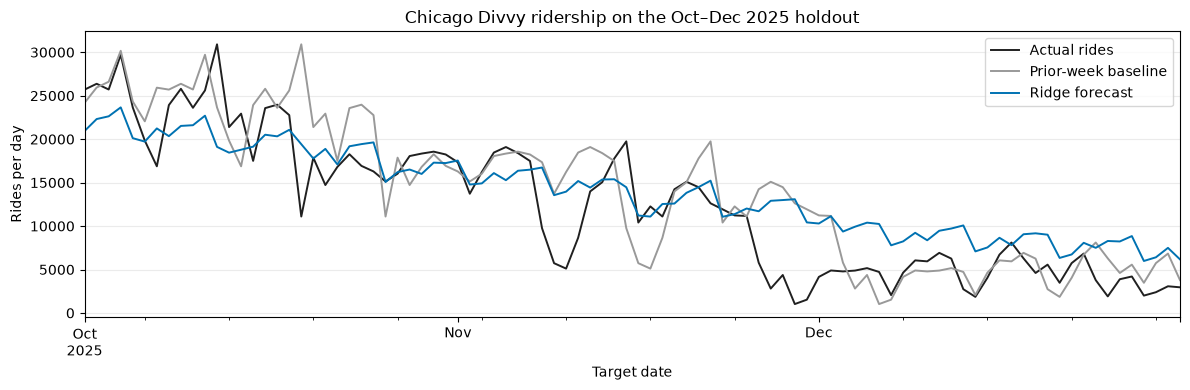

In [6]:
import matplotlib.pyplot as plt

ax = results[["actual", "prior_week", "ridge"]].rename(columns={
    "actual": "Actual rides",
    "prior_week": "Prior-week baseline",
    "ridge": "Ridge forecast",
}).plot(
    figsize=(12, 4),
    color=["#202020", "#999999", "#0072B2"],
    linewidth=1.4,
)

ax.set(
    title="Chicago Divvy ridership on the Oct–Dec 2025 holdout",
    xlabel="Target date",
    ylabel="Rides per day",
)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()